## This is an example of illustrating how to auto-tune the TiVy window sizes through grid search

In [7]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


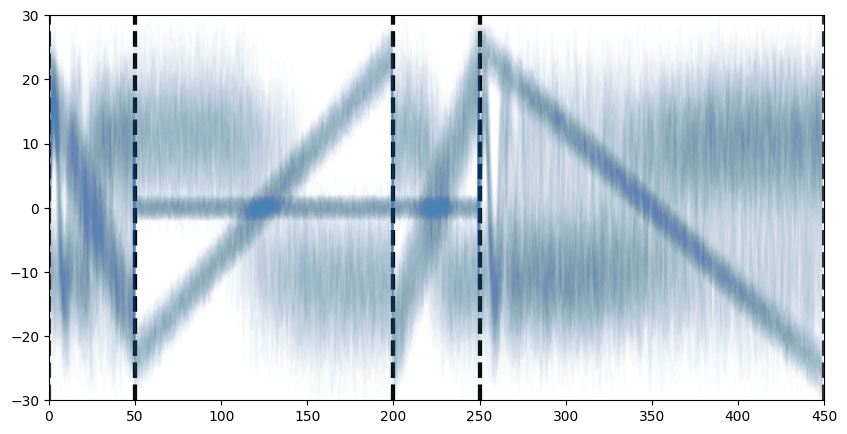

In [8]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from TSVis.synthetic_data import generateSyntheticData

fig, ax = plt.subplots(figsize=(10, 5))

plt.ylim(-30, 30)
plt.margins(x=0)

ts = []

data = generateSyntheticData(100,50)
cyclic = data[4]/np.max(data[4]) * 30
decreasing = data[1] / np.max(data[1]) * 30
upward = data[5]/np.max(data[5]) * 30
t1 = np.concatenate((cyclic,decreasing,upward))

data = generateSyntheticData(100,150)
normal = data[0]
increasing = data[2]  /np.max(data[2]) * 30
downward = data[3]/np.max(data[3]) * 30
t2 = np.concatenate((normal,increasing,downward))


data = generateSyntheticData(100,200)
cyclic = data[4]/np.max(data[4]) * 30
decreasing = data[1] / np.max(data[1]) * 30
upward = data[5]/np.max(data[5]) * 30
t4 = np.concatenate((cyclic,decreasing,upward))

data = generateSyntheticData(100,50)
normal = data[0]
increasing = data[2]  /np.max(data[2]) * 30
downward = data[3]/np.max(data[3]) * 30
t3 = np.concatenate((normal,increasing,downward))

random_idx_1 = np.arange(t1.shape[0])
random_idx_2 = np.arange(t2.shape[0])
random_idx_3 = np.arange(t3.shape[0])
random_idx_4 = np.arange(t4.shape[0])

np.random.shuffle(random_idx_1)
np.random.shuffle(random_idx_2)
np.random.shuffle(random_idx_3)
np.random.shuffle(random_idx_4)

t_4 = np.concatenate((t1[random_idx_1,:],t2[random_idx_2,:],t3[random_idx_3,:],t4[random_idx_4,:]),1)
t_4.shape

time_ranges = [[0,50],[50,200],[200,250],[250,450]]
for i, (start, end) in enumerate(time_ranges):
    ax.axvline(x=start, color='black', linestyle='--', alpha=0.8, linewidth=3)
    ax.axvline(x=end, color='black', linestyle='--', alpha=0.8, linewidth=3)
    
ax.plot(t_4.T,c='steelblue',alpha=0.01)

plt.savefig('exp_1_different_intervals.png')

In [9]:
from TiVy import *

data = t_4
grid_search_spec = {'min_support':80,'min_length':50,'min_size':1,'min_scan_support':80}

# min window size = 50
i = 9
chunk_size = data.shape[1] / i

tivy = TiVy(chunk_size=chunk_size,strength=1.5,steps=0,segment = False,cutoff=0,grid_search_spec=grid_search_spec,use_LSH=True, nPerm=20, bandWidth=0.5)

tivy.grid_search_clustering(data)

start clustering


100%|█████████████████████████████████████████| 256/256 [05:32<00:00,  1.30s/it]

end clustering


In [10]:
# create support profile
tivy.grid_search_scanning()
# evaluate each cluster results
best_cluster, cluster_ranks = cluster_evaluation(tivy.clusters_combinations,tivy.data)

256it [00:00, 1148.42it/s]


In [14]:
# example time ranges of the best cluster combination
time_ranges = tivy.clusters_combinations[best_cluster]['time_range']
time_ranges

[0,
 np.int64(50),
 np.int64(100),
 np.int64(150),
 np.int64(200),
 np.int64(250),
 np.int64(300),
 np.int64(350),
 np.int64(400),
 np.int64(450)]

In [18]:
# create buffers for visualization
from TSVis.widget import TimeSeriesVis
result = tivy.output_result(tivy.clusters_combinations[cluster_ranks[0]]['result'],return_idx=True)
summary = TimeSeriesVis(n_cols=3,padding=50,n_ticks=3,chart_width=260,chart_height=140,interpolate=500)
summary.fit(result['result'])

Preparing Buffer...


  0%|          | 0/11 [00:00<?, ?it/s]

/Users/ychan/Codes/TiVy-git/tivy_env/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Box(children=(Label(value='Show Lines'), Checkbox(value=False, description='|', indent=False, layout=Layout(wi…

RFBOutputContext()

CanvasBackend(css_height='760px', css_width='930px')
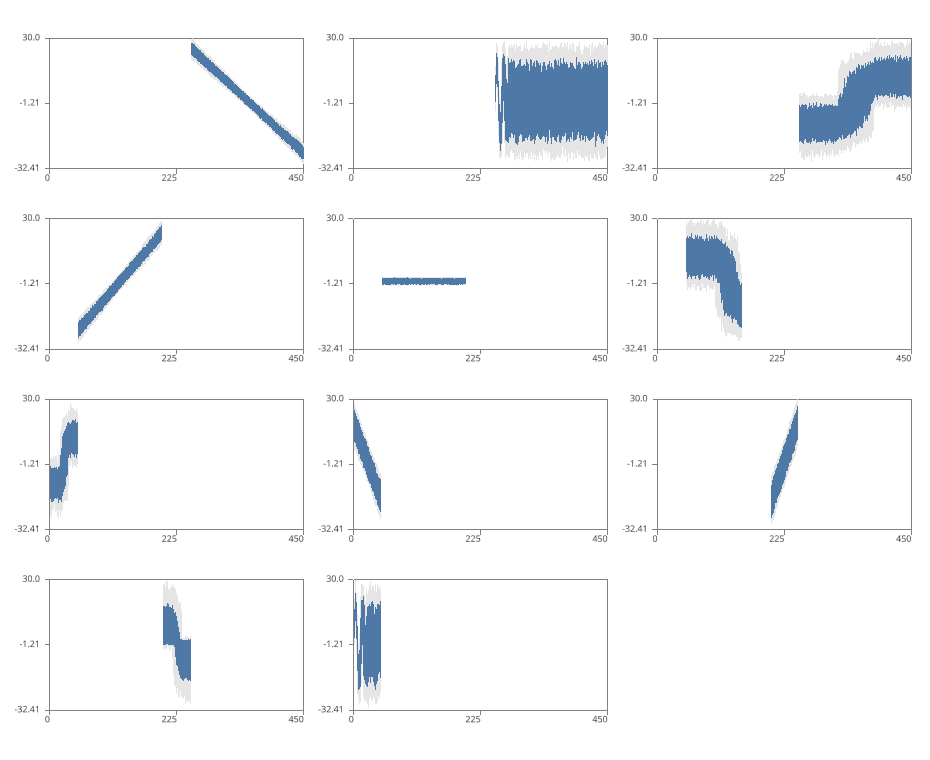

In [19]:
# render the result
summary.visualize()